In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROUND = 2
DAYS = [-1, 0, 1]

price_files, trade_files = {}, {}

for day in DAYS:
    price_file = {day: f"data/prices_round_{ROUND}_day_{day}.csv"}
    trade_file = {day: f"data/trades_round_{ROUND}_day_{day}.csv"}
    price_files.update(price_file)
    trade_files.update(trade_file)



# Load and offset timestamps by 1M steps
OFFSET = 1_000_000 # each day has 1 million steps
def read_prices(product: str):
        dfs = []
        for i, (day, pf) in enumerate(price_files.items()):
            df = pd.read_csv(pf, sep=';')
            df = df[df['product'] == product].copy()
            df['timestamp'] += i * OFFSET
            df['day'] = day
            df['wall_mid'] = (df[['bid_price_1', 'bid_price_2', 'bid_price_3']].min(axis=1) + df[['ask_price_1', 'ask_price_2', 'ask_price_3']].max(axis=1)) / 2
            df['spread'] = df['ask_price_1'] - df['bid_price_1']
            dfs.append(df)
        return pd.concat(dfs, ignore_index=True).sort_values('timestamp')

def read_trades(symbol: str):
        dfs = []
        for i, (day, pf) in enumerate(trade_files.items()):
            df = pd.read_csv(pf, sep=';')
            df = df[df['symbol'] == symbol].copy()
            df['timestamp'] += i * OFFSET
            df['day'] = day
            
            
            
            
            dfs.append(df)
        return pd.concat(dfs, ignore_index=True).sort_values('timestamp')

# Combine
osmium_prices = read_prices('ASH_COATED_OSMIUM')
osmium_trades = read_trades('ASH_COATED_OSMIUM')
pepper_prices = read_prices('INTARIAN_PEPPER_ROOT')
pepper_trades = read_trades('INTARIAN_PEPPER_ROOT')


osmium_prices['fixed_price'] = 10000

osmium_prices.head(10)
osmium_prices.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   day              30000 non-null  int64  
 1   timestamp        30000 non-null  int64  
 2   product          30000 non-null  object 
 3   bid_price_1      28804 non-null  float64
 4   bid_volume_1     28804 non-null  float64
 5   bid_price_2      19524 non-null  float64
 6   bid_volume_2     19524 non-null  float64
 7   bid_price_3      704 non-null    float64
 8   bid_volume_3     704 non-null    float64
 9   ask_price_1      28851 non-null  float64
 10  ask_volume_1     28851 non-null  float64
 11  ask_price_2      19674 non-null  float64
 12  ask_volume_2     19674 non-null  float64
 13  ask_price_3      733 non-null    float64
 14  ask_volume_3     733 non-null    float64
 15  mid_price        30000 non-null  float64
 16  profit_and_loss  30000 non-null  float64
 17  wall_mid    

<Axes: >

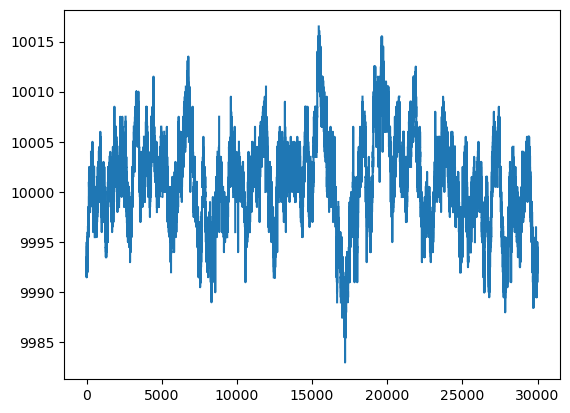

In [5]:
osmium_prices["wall_mid"].plot()